# Show the Scores by Level

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# --- Paths ---
elpac_dir = "../1095 Data/ELPAC/"
enrollment_dir = "../1095 Data/Enrollment"
group_csv = "group_c_ssids.csv"

os.makedirs("plots", exist_ok=True)

# --- Load Group C SSIDs ---
group_ssids = set(pd.read_csv(group_csv)["SSID"])
print(f"Group C: {len(group_ssids):,} students")

# --- Load Enrollment for grade level ---
enrollment_files = {
    "2021-22": "CEnrollment_21-22.csv",
    "2022-23": "CEnrollment_22-23.csv",
    "2023-24": "CEnrollment_23-24.csv",
}
enrollments = {}
for label, filename in enrollment_files.items():
    enrollments[label] = pd.read_csv(os.path.join(enrollment_dir, filename), low_memory=False)

enrollment_all = pd.concat(enrollments.values(), ignore_index=True)
enrollment_all = enrollment_all.drop_duplicates(subset="SSID", keep="first")
enrollment_c = enrollment_all[enrollment_all["SSID"].isin(group_ssids)][["SSID", "GradeLevelCode"]]
print(f"Group C enrollment records: {len(enrollment_c):,}")

# --- Load Summative ELPAC files ---
summative_files = {
    1: "SummativeElpac_22.csv",
    2: "SummativeElpac_23.csv",
    3: "SummativeElpac_24.csv",
}

summative_dfs = {}
for year_num, filename in summative_files.items():
    df = pd.read_csv(os.path.join(elpac_dir, filename))
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["OverallScaleScore"] = pd.to_numeric(df["OverallScaleScore"], errors="coerce")
    df["TestStartDate"] = pd.to_datetime(df["TestStartDate"], errors="coerce")
    summative_dfs[year_num] = df

# --- Load Initial ELPAC to get first test date ---
initial_files = {
    "Initial 2022": "InitialElpac_22.csv",
    "Initial 2023": "InitialElpac_23.csv",
    "Initial 2024": "InitialElpac_24.csv",
}

initial_dfs = {}
for label, filename in initial_files.items():
    df = pd.read_csv(os.path.join(elpac_dir, filename))
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["TestStartDate"] = pd.to_datetime(df["TestStartDate"], errors="coerce")
    initial_dfs[label] = df

first_initial_date = {}
for label, df in initial_dfs.items():
    df_group = df[df["SSID"].isin(group_ssids)][["SSID", "TestStartDate"]].dropna()
    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        if ssid not in first_initial_date or row["TestStartDate"] < first_initial_date[ssid]:
            first_initial_date[ssid] = row["TestStartDate"]

print(f"Students with initial test date: {len(first_initial_date):,}")

Group C: 28,055 students
Group C enrollment records: 28,055
Students with initial test date: 28,055


In [2]:
# --- ELPAC Summative Level Lookup Table ---
# Each entry: grade_key -> [(level, min_score, max_score), ...]
elpac_levels = {
    "KN": [(1, 1150, 1373), (2, 1374, 1421), (3, 1422, 1473), (4, 1474, 1700)],
    "01": [(1, 1150, 1410), (2, 1411, 1454), (3, 1455, 1506), (4, 1507, 1700)],
    "02": [(1, 1150, 1423), (2, 1424, 1470), (3, 1471, 1531), (4, 1532, 1700)],
    "03": [(1, 1150, 1447), (2, 1448, 1487), (3, 1488, 1534), (4, 1535, 1800)],
    "04": [(1, 1150, 1458), (2, 1459, 1498), (3, 1499, 1548), (4, 1549, 1800)],
    "05": [(1, 1150, 1466), (2, 1467, 1513), (3, 1514, 1559), (4, 1560, 1800)],
    "06": [(1, 1150, 1474), (2, 1475, 1516), (3, 1517, 1566), (4, 1567, 1900)],
    "07": [(1, 1150, 1480), (2, 1481, 1526), (3, 1527, 1575), (4, 1576, 1900)],
    "08": [(1, 1150, 1485), (2, 1486, 1533), (3, 1534, 1589), (4, 1590, 1900)],
    "09": [(1, 1150, 1492), (2, 1493, 1544), (3, 1545, 1605), (4, 1606, 1950)],
    "10": [(1, 1150, 1492), (2, 1493, 1544), (3, 1545, 1605), (4, 1606, 1950)],
    "11": [(1, 1150, 1499), (2, 1500, 1554), (3, 1555, 1614), (4, 1615, 1950)],
    "12": [(1, 1150, 1499), (2, 1500, 1554), (3, 1555, 1614), (4, 1615, 1950)],
}

def score_to_level(score, grade):
    grade = str(grade).strip()
    if grade not in elpac_levels or pd.isna(score):
        return None
    for level, low, high in elpac_levels[grade]:
        if low <= score <= high:
            return level
    return None

In [3]:
# --- Build per-student ordered summative records (sorted by date) ---
# Deduplicate to one record per student per year (highest score)
student_summatives = {}  # SSID -> sorted list of (date, score, grade)

# Merge grade level into each summative file and collect records
for year_num, df in summative_dfs.items():
    df_group = df[df["SSID"].isin(group_ssids)].copy()
    df_group = df_group.merge(enrollment_c, on="SSID", how="left")
    df_group = df_group.dropna(subset=["OverallScaleScore", "TestStartDate", "GradeLevelCode"])

    # Deduplicate: keep highest score per student for this year
    df_group = df_group.loc[df_group.groupby("SSID")["OverallScaleScore"].idxmax()]

    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        init_date = first_initial_date.get(ssid)
        if init_date is None or row["TestStartDate"] <= init_date:
            continue
        if ssid not in student_summatives:
            student_summatives[ssid] = []
        student_summatives[ssid].append((
            row["TestStartDate"],
            row["OverallScaleScore"],
            row["GradeLevelCode"]
        ))

# Sort each student's summatives by date and keep only first 3
for ssid in student_summatives:
    student_summatives[ssid] = sorted(student_summatives[ssid], key=lambda x: x[0])[:3]

# Build a flat dataframe with test number, score, grade, and level
records = []
for ssid, tests in student_summatives.items():
    if len(tests) == 3:
        for test_num, (date, score, grade) in enumerate(tests, start=1):
            level = score_to_level(score, grade)
            records.append({
                "SSID":          ssid,
                "TestNumber":    test_num,
                "TestDate":      date,
                "Score":         score,
                "GradeLevelCode": grade,
                "Level":         level
            })

scored_df = pd.DataFrame(records)
print(f"Total scored records: {len(scored_df):,}")
print(f"Level distribution:\n{scored_df['Level'].value_counts().sort_index()}")

Total scored records: 84,165
Level distribution:
Level
1.0    26475
2.0    21621
3.0    24138
4.0    11840
Name: count, dtype: int64


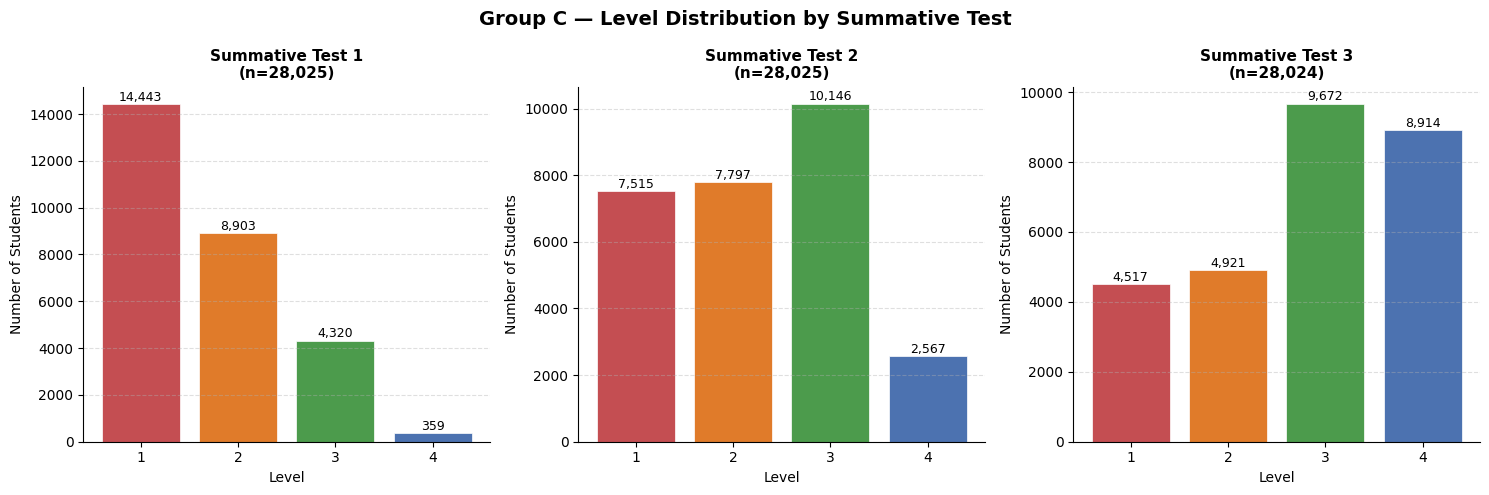

Saved: plots/group_c_level_distribution_overall.png


In [4]:
# --- 3 histograms: Level distribution for Test 1, 2, 3 (all students) ---
level_colors = {1: "#C44E52", 2: "#E07B2A", 3: "#4C9B4C", 4: "#4C72B0"}
group_name = os.path.splitext(os.path.basename(group_csv))[0].replace("_ssids", "").replace("_", " ").title()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(f"{group_name} — Level Distribution by Summative Test", fontsize=14, fontweight="bold")

for ax, test_num in zip(axes, [1, 2, 3]):
    test_data = scored_df[scored_df["TestNumber"] == test_num]["Level"].dropna()
    counts = test_data.value_counts().sort_index()
    colors = [level_colors.get(l, "#999999") for l in counts.index]
    bars = ax.bar(counts.index, counts.values, color=colors, edgecolor="white", linewidth=0.5)

    for bar, count in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                f"{count:,}", ha="center", va="bottom", fontsize=9)

    ax.set_title(f"Summative Test {test_num}\n(n={len(test_data):,})", fontsize=11, fontweight="bold")
    ax.set_xlabel("Level", fontsize=10)
    ax.set_ylabel("Number of Students", fontsize=10)
    ax.set_xticks([1, 2, 3, 4])
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"plots/group_c_level_distribution_overall.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/group_c_level_distribution_overall.png")

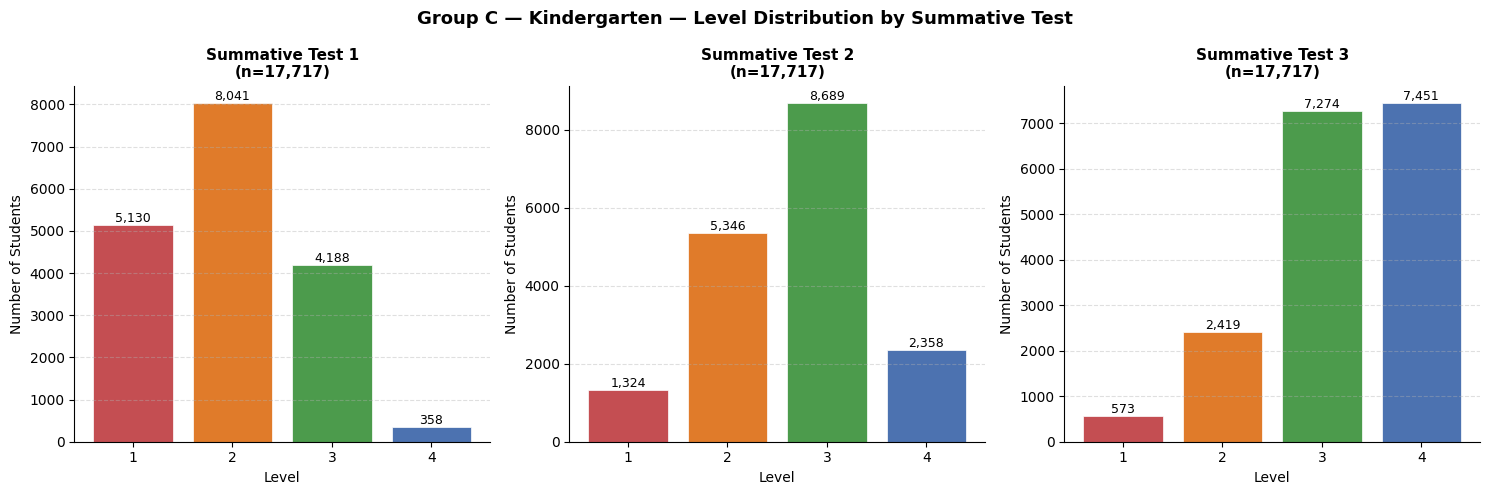

Saved: plots/group_c_level_distribution_KN.png


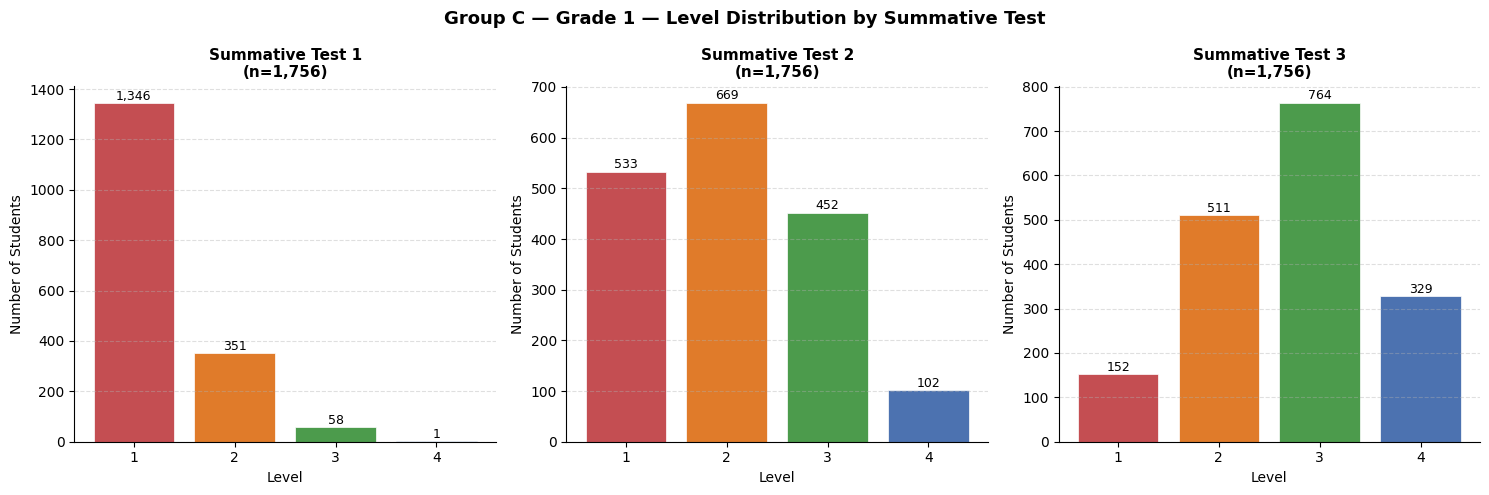

Saved: plots/group_c_level_distribution_01.png


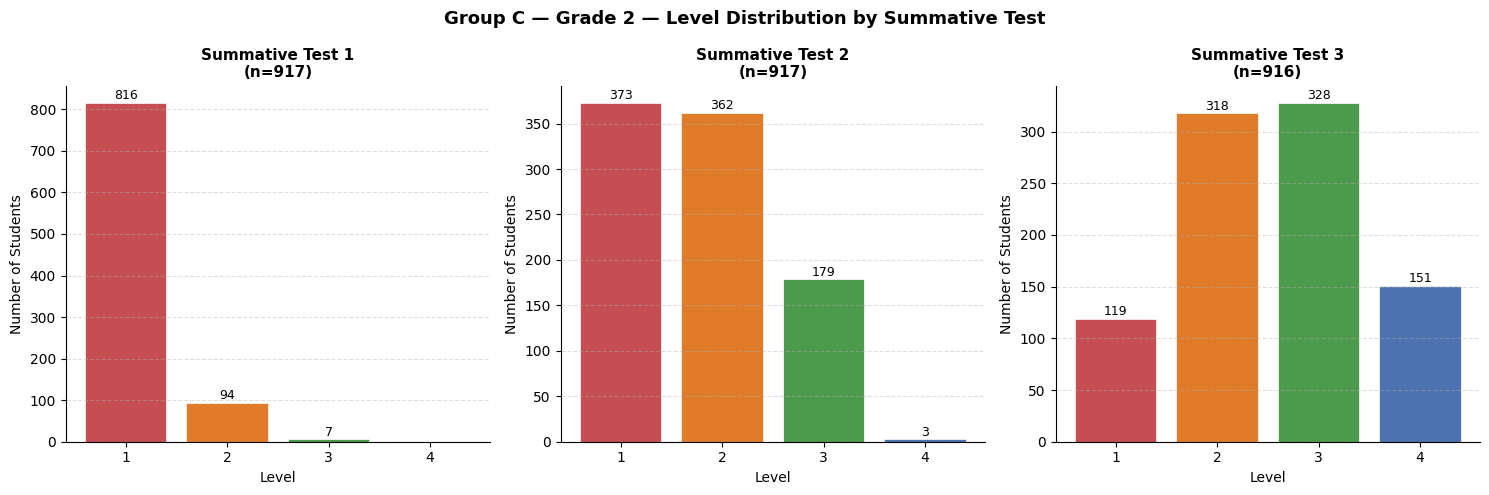

Saved: plots/group_c_level_distribution_02.png


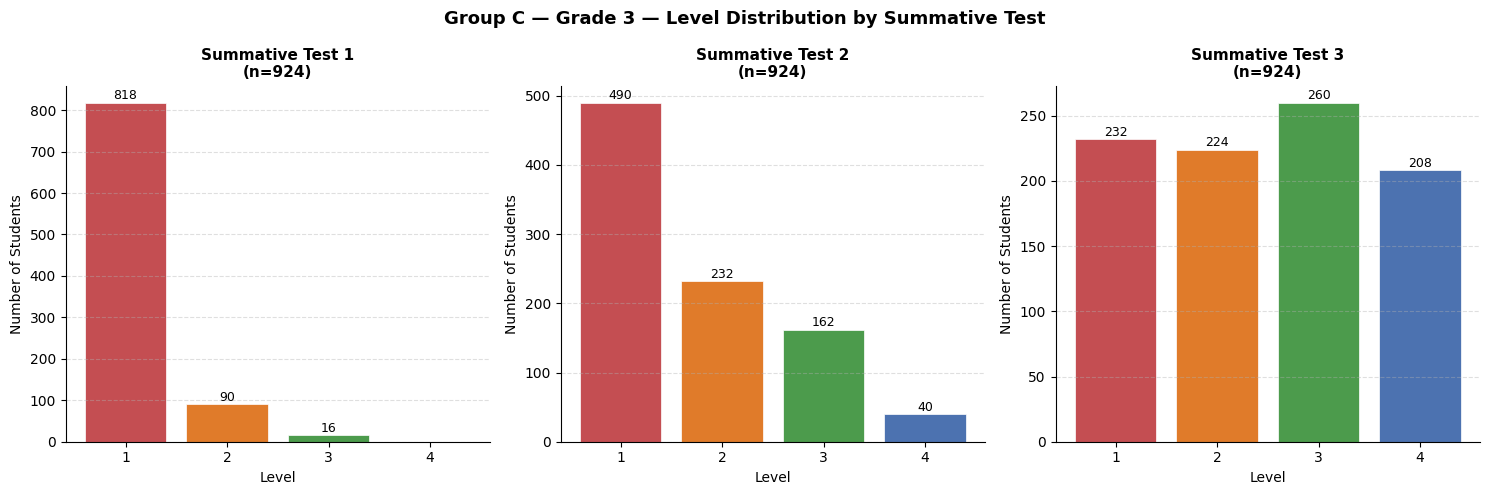

Saved: plots/group_c_level_distribution_03.png


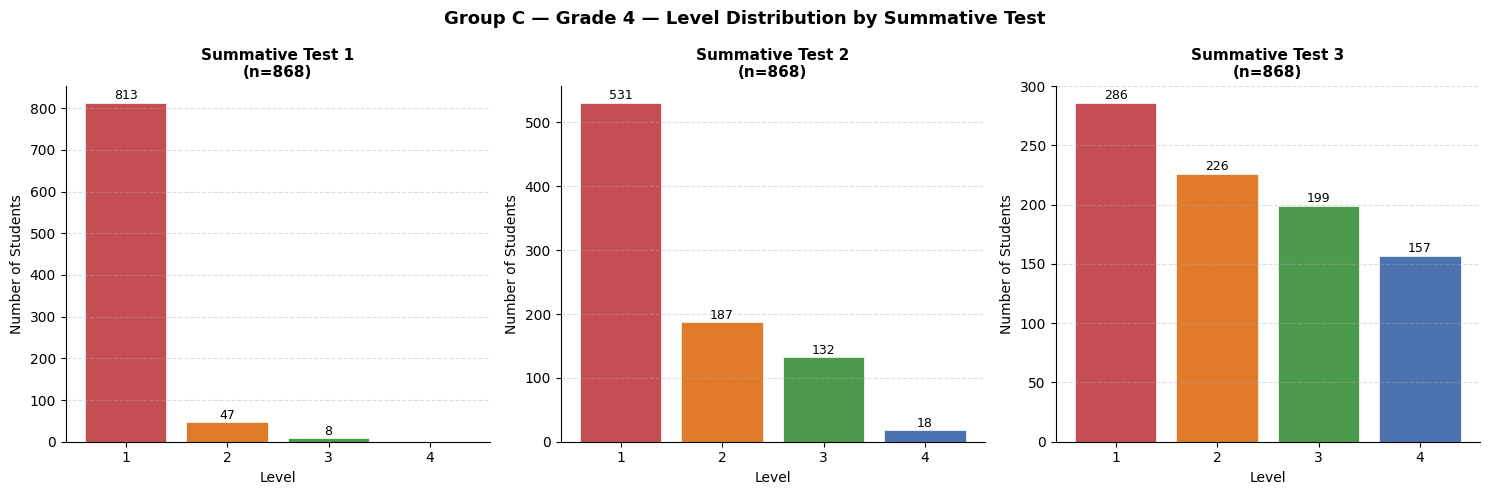

Saved: plots/group_c_level_distribution_04.png


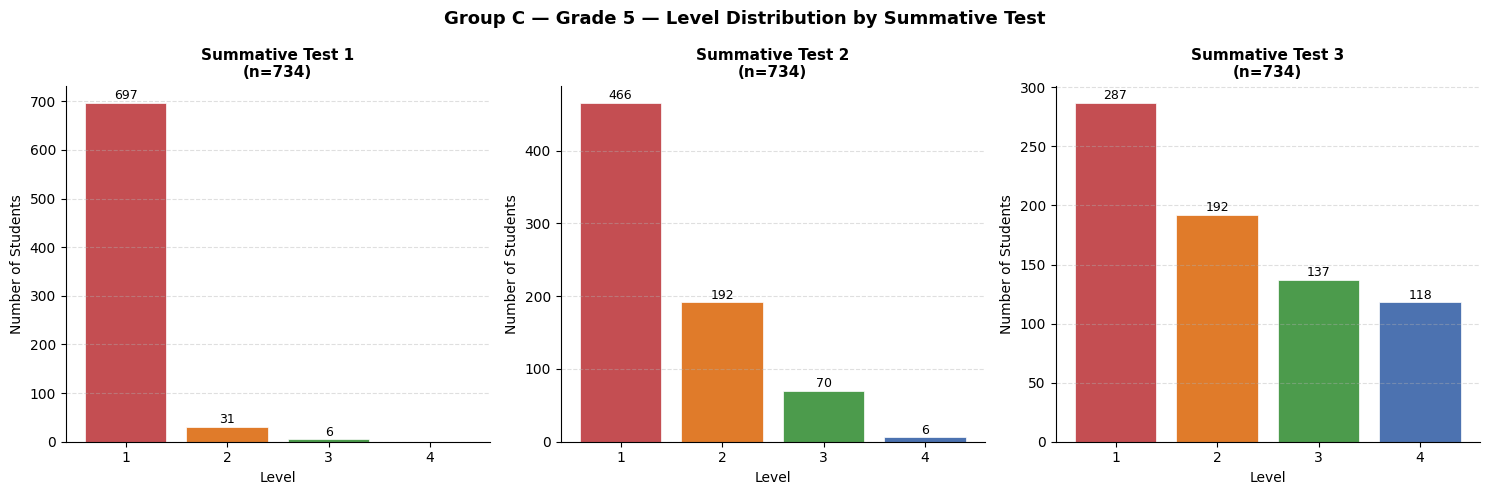

Saved: plots/group_c_level_distribution_05.png


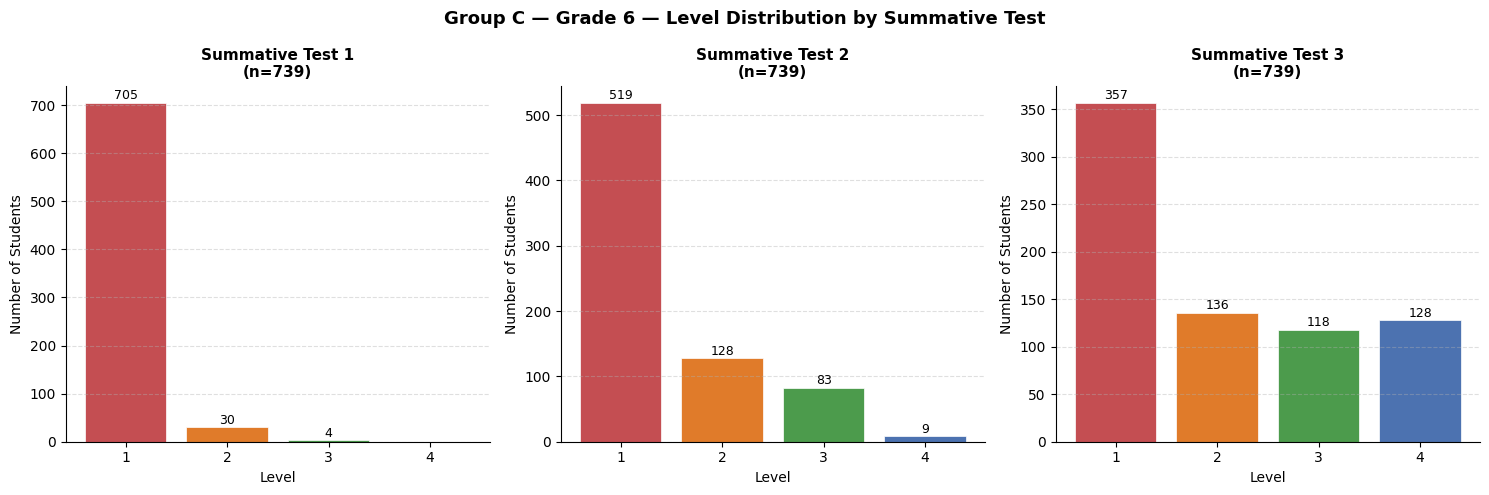

Saved: plots/group_c_level_distribution_06.png


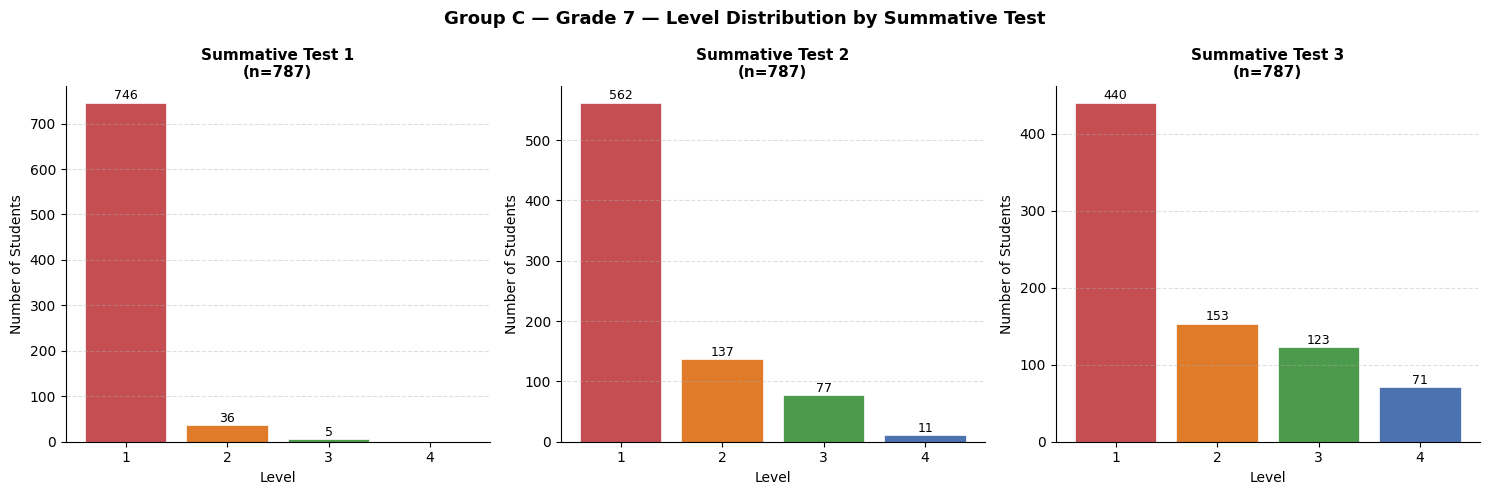

Saved: plots/group_c_level_distribution_07.png


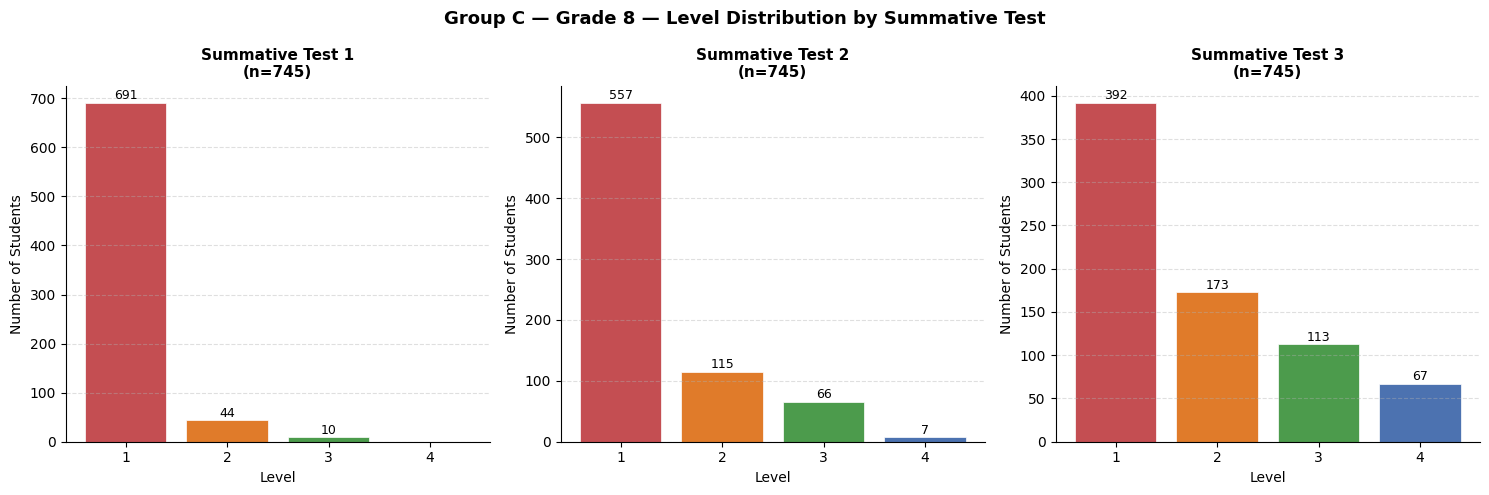

Saved: plots/group_c_level_distribution_08.png


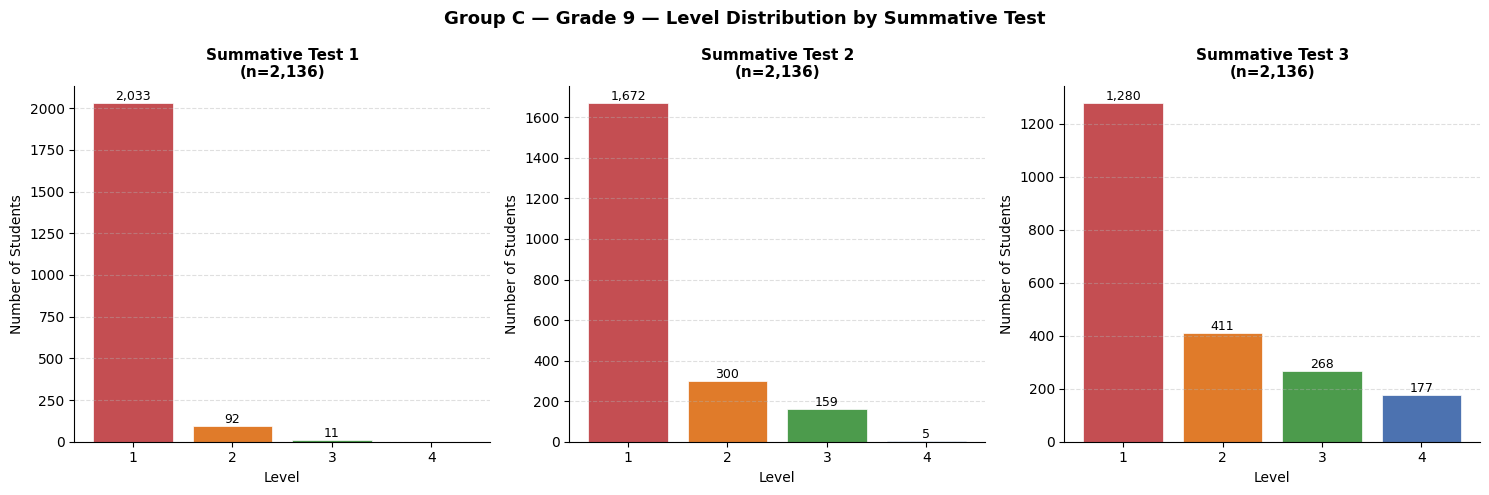

Saved: plots/group_c_level_distribution_09.png


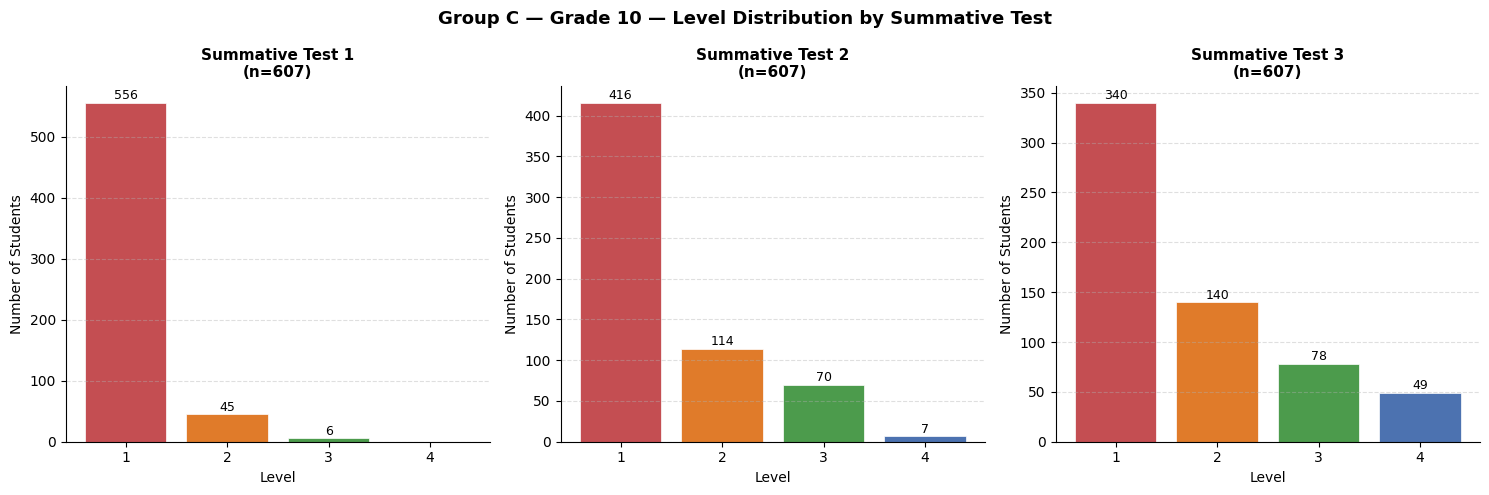

Saved: plots/group_c_level_distribution_10.png


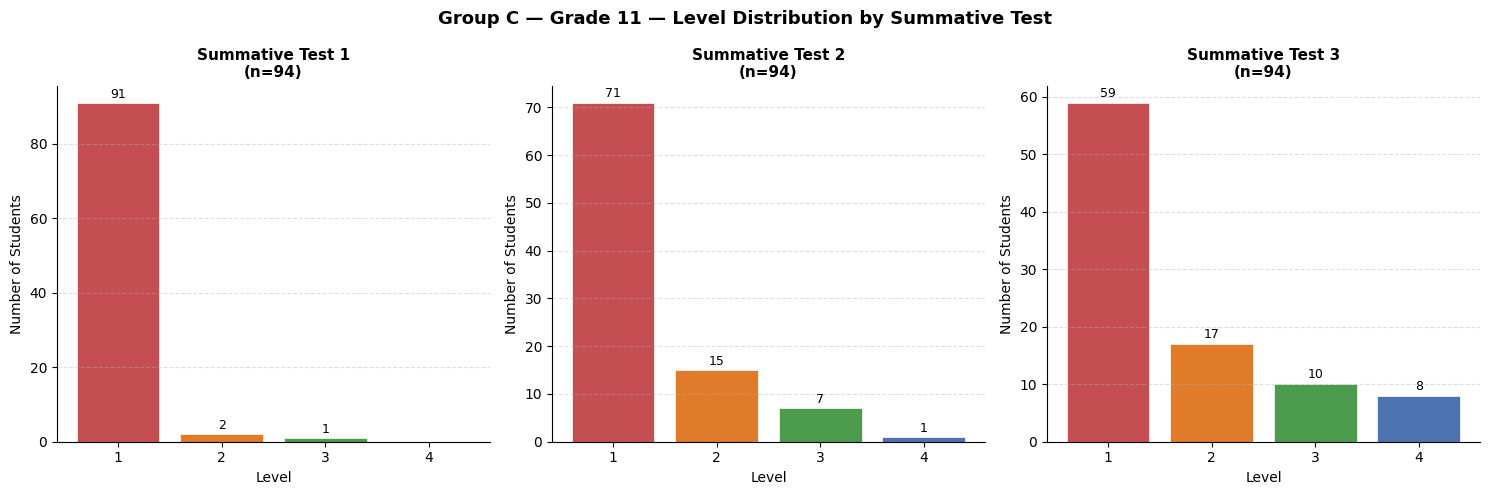

Saved: plots/group_c_level_distribution_11.png


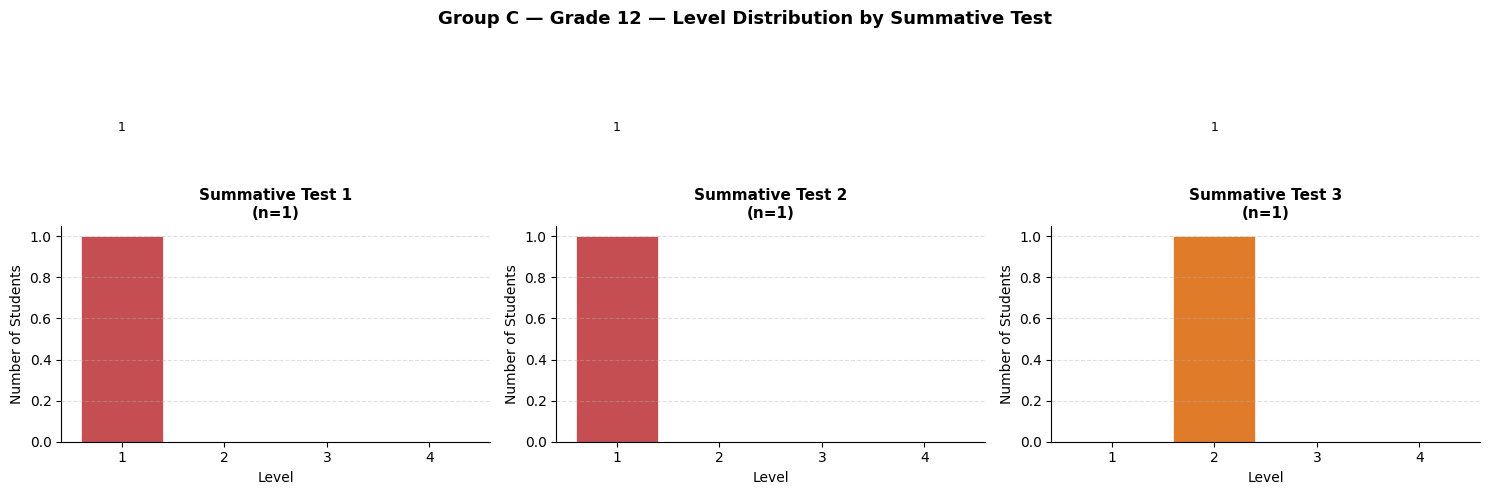

Saved: plots/group_c_level_distribution_12.png


In [5]:
# --- Per-grade level histograms: one figure per grade, 3 subplots ---
grade_order = ["KN", "01", "02", "03", "04", "05", "06", "07", "08", "09", "10", "11", "12"]
grade_labels = {
    "KN": "Kindergarten", "01": "Grade 1",  "02": "Grade 2",
    "03": "Grade 3",      "04": "Grade 4",  "05": "Grade 5",
    "06": "Grade 6",      "07": "Grade 7",  "08": "Grade 8",
    "09": "Grade 9",      "10": "Grade 10", "11": "Grade 11", "12": "Grade 12"
}

grades_present = [g for g in grade_order if g in scored_df["GradeLevelCode"].values]

for grade in grades_present:
    grade_data = scored_df[scored_df["GradeLevelCode"] == grade]
    if len(grade_data) == 0:
        continue

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"{group_name} — {grade_labels[grade]} — Level Distribution by Summative Test",
                 fontsize=13, fontweight="bold")

    for ax, test_num in zip(axes, [1, 2, 3]):
        test_data = grade_data[grade_data["TestNumber"] == test_num]["Level"].dropna()
        counts = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        colors = [level_colors[l] for l in counts.index]
        bars = ax.bar(counts.index, counts.values, color=colors, edgecolor="white", linewidth=0.5)

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=9)

        ax.set_title(f"Summative Test {test_num}\n(n={len(test_data):,})", fontsize=11, fontweight="bold")
        ax.set_xlabel("Level", fontsize=10)
        ax.set_ylabel("Number of Students", fontsize=10)
        ax.set_xticks([1, 2, 3, 4])
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"plots/group_c_level_distribution_{grade}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/group_c_level_distribution_{grade}.png")

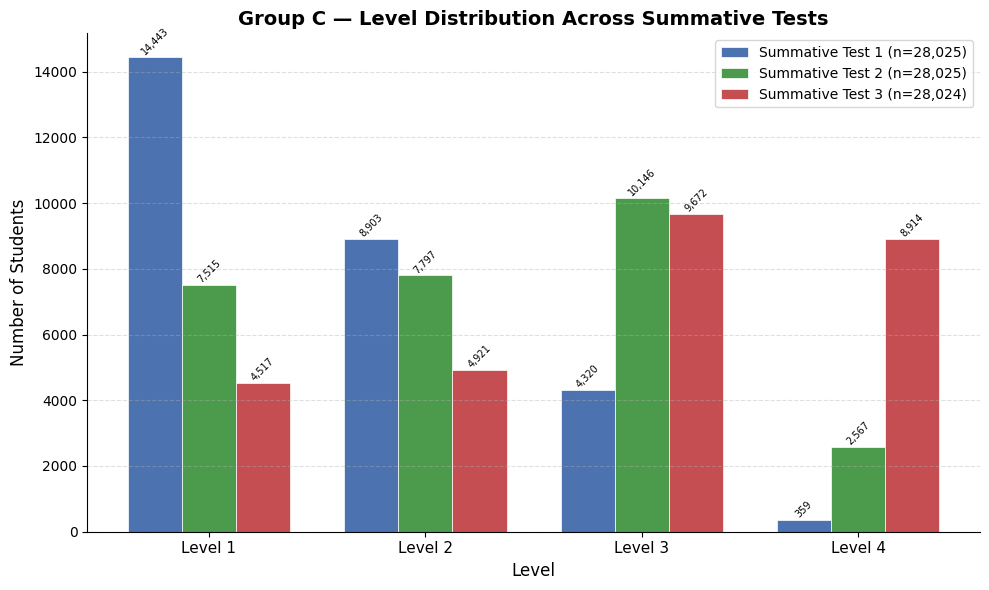

Saved: plots/group_c_level_distribution_combined.png


In [6]:
# --- Grouped bar chart: all 3 tests on one figure ---
fig, ax = plt.subplots(figsize=(10, 6))

x = np.array([1, 2, 3, 4])
width = 0.25
offsets = [-width, 0, width]
test_colors = ["#4C72B0", "#4C9B4C", "#C44E52"]

for i, test_num in enumerate([1, 2, 3]):
    test_data = scored_df[scored_df["TestNumber"] == test_num]["Level"].dropna()
    counts = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
    bars = ax.bar(x + offsets[i], counts.values, width=width,
                  color=test_colors[i], edgecolor="white", linewidth=0.5,
                  label=f"Summative Test {test_num} (n={len(test_data):,})")

    for bar, count in zip(bars, counts.values):
        if count > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                    f"{count:,}", ha="center", va="bottom", fontsize=7, rotation=45)

ax.set_xticks(x)
ax.set_xticklabels(["Level 1", "Level 2", "Level 3", "Level 4"], fontsize=11)
ax.set_xlabel("Level", fontsize=12)
ax.set_ylabel("Number of Students", fontsize=12)
ax.set_title(f"{group_name} — Level Distribution Across Summative Tests",
             fontsize=14, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("plots/group_c_level_distribution_combined.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/group_c_level_distribution_combined.png")

Students with Level 1 on Test 1: 14,443
Of those, with a Test 3 score: 14,442

Level 1 on Test 1 → Level on Test 3:
  Level 1: 4,421 students (30.6%)
  Level 2: 3,949 students (27.3%)
  Level 3: 4,218 students (29.2%)
  Level 4: 1,854 students (12.8%)


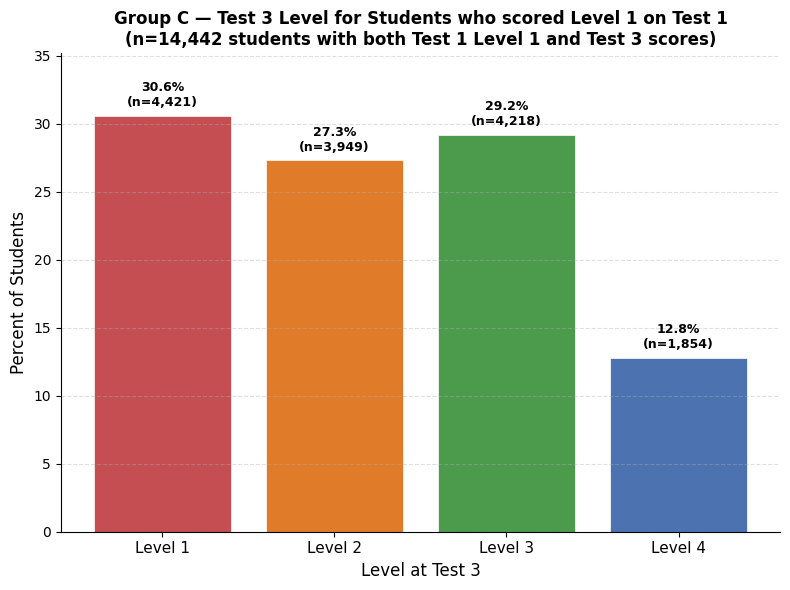

Saved: plots/group_c_level1_test1_progression.png


In [7]:
# --- Students who scored Level 1 on Test 1 ---
test1_level1 = scored_df[
    (scored_df["TestNumber"] == 1) & (scored_df["Level"] == 1)
]["SSID"].unique()

print(f"Students with Level 1 on Test 1: {len(test1_level1):,}")

# --- Find their level on Test 3 ---
test3_scores = scored_df[
    (scored_df["TestNumber"] == 3) & (scored_df["SSID"].isin(test1_level1))
][["SSID", "Level"]].dropna()

print(f"Of those, with a Test 3 score: {len(test3_scores):,}")

# --- Count and percent by Test 3 level ---
level_counts = test3_scores["Level"].value_counts().reindex([1, 2, 3, 4], fill_value=0)
level_pcts = (level_counts / len(test3_scores) * 100).round(1)

print(f"\nLevel 1 on Test 1 → Level on Test 3:")
for level in [1, 2, 3, 4]:
    print(f"  Level {level}: {level_counts[level]:,} students ({level_pcts[level]}%)")

# --- Bar chart ---
fig, ax = plt.subplots(figsize=(8, 6))

colors = [level_colors[l] for l in [1, 2, 3, 4]]
bars = ax.bar([1, 2, 3, 4], level_pcts.values, color=colors, edgecolor="white", linewidth=0.5)

for bar, count, pct in zip(bars, level_counts.values, level_pcts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f"{pct}%\n(n={count:,})", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(["Level 1", "Level 2", "Level 3", "Level 4"], fontsize=11)
ax.set_xlabel("Level at Test 3", fontsize=12)
ax.set_ylabel("Percent of Students", fontsize=12)
ax.set_title(f"{group_name} — Test 3 Level for Students who scored Level 1 on Test 1\n"
             f"(n={len(test3_scores):,} students with both Test 1 Level 1 and Test 3 scores)",
             fontsize=12, fontweight="bold")
ax.set_ylim(0, max(level_pcts.values) * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("plots/group_c_level1_test1_progression.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/group_c_level1_test1_progression.png")

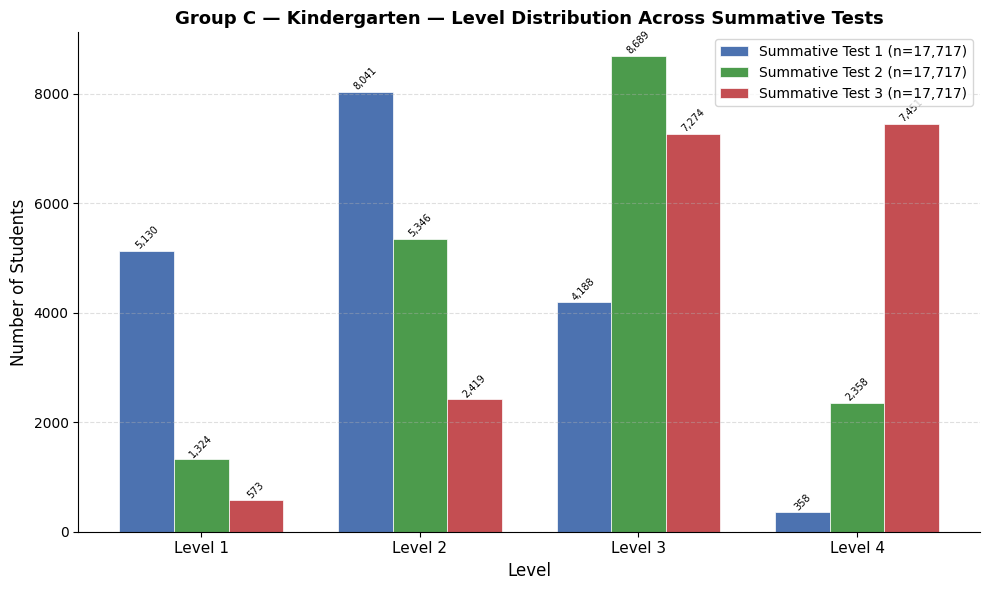

Saved: plots/group_c_level_distribution_combined_KN.png


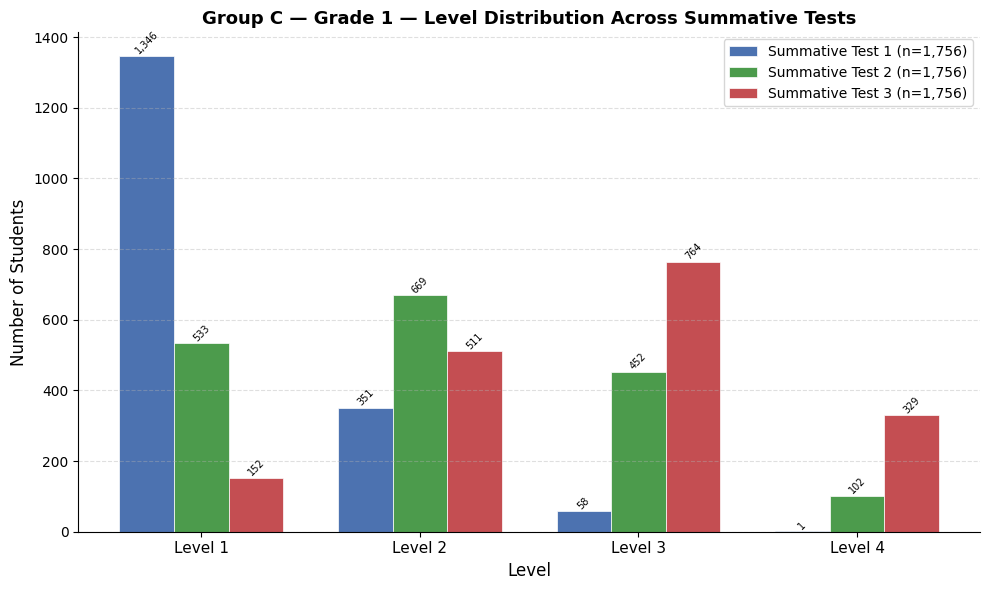

Saved: plots/group_c_level_distribution_combined_01.png


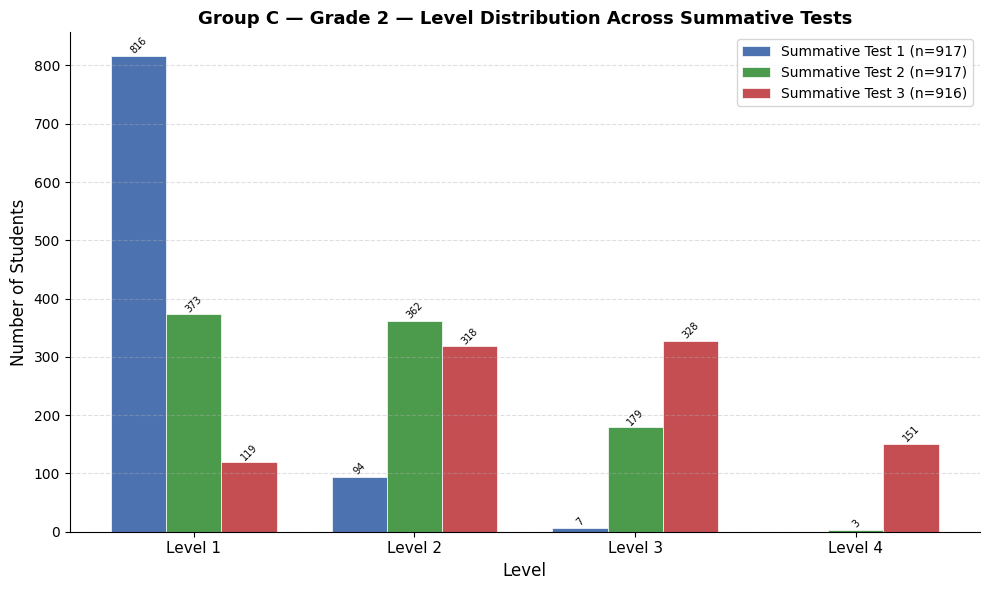

Saved: plots/group_c_level_distribution_combined_02.png


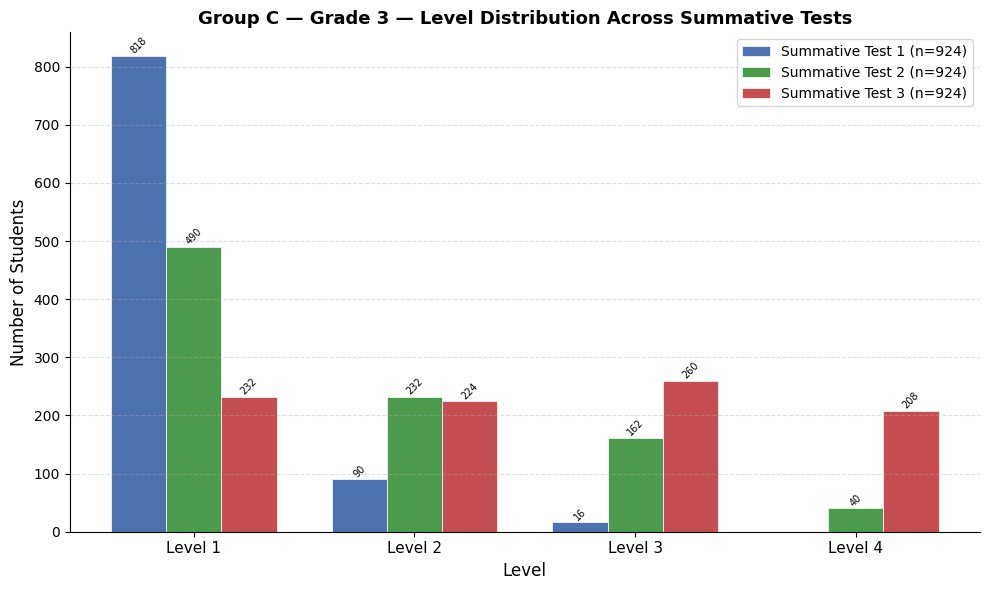

Saved: plots/group_c_level_distribution_combined_03.png


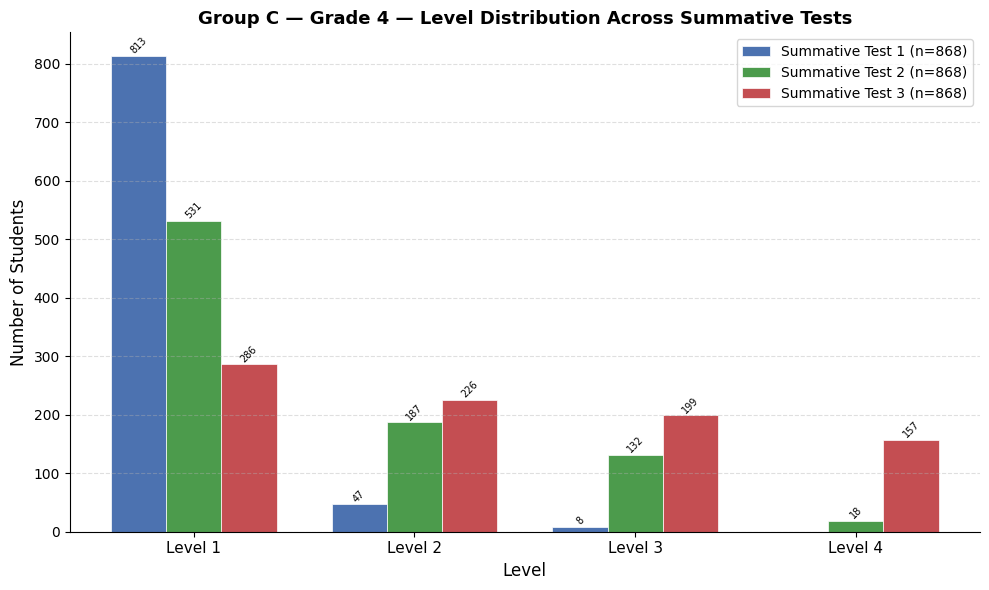

Saved: plots/group_c_level_distribution_combined_04.png


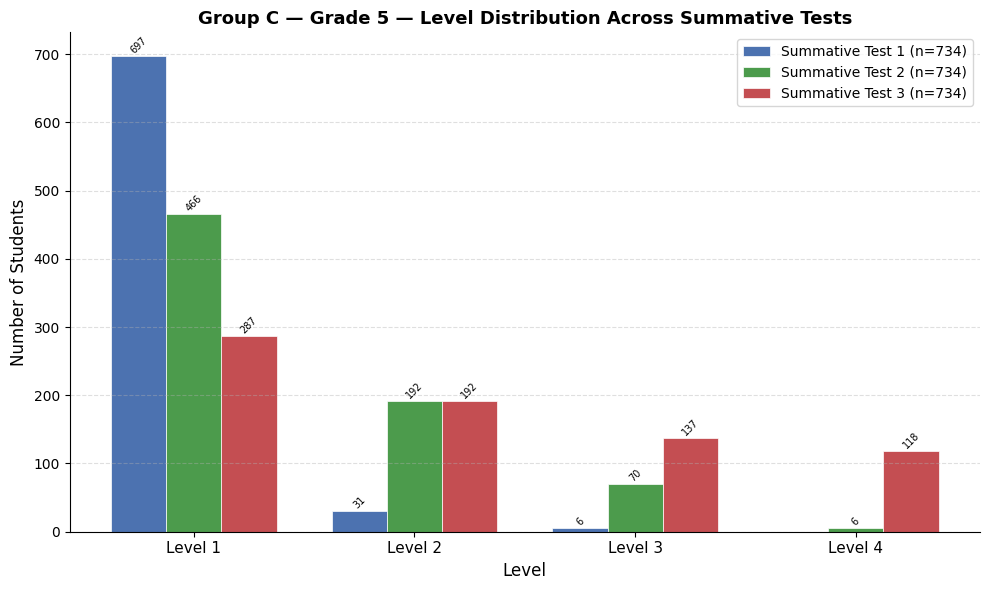

Saved: plots/group_c_level_distribution_combined_05.png


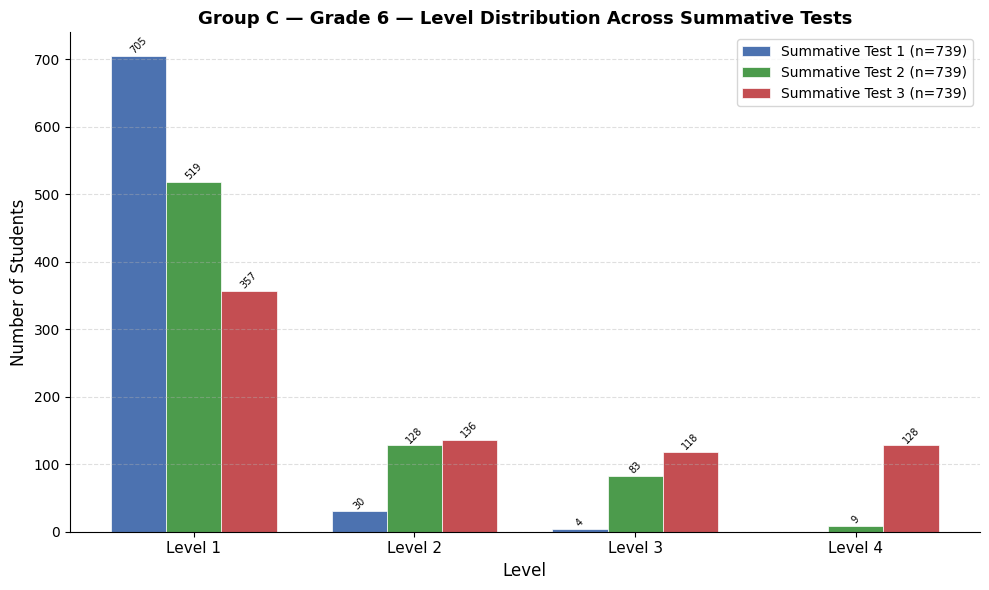

Saved: plots/group_c_level_distribution_combined_06.png


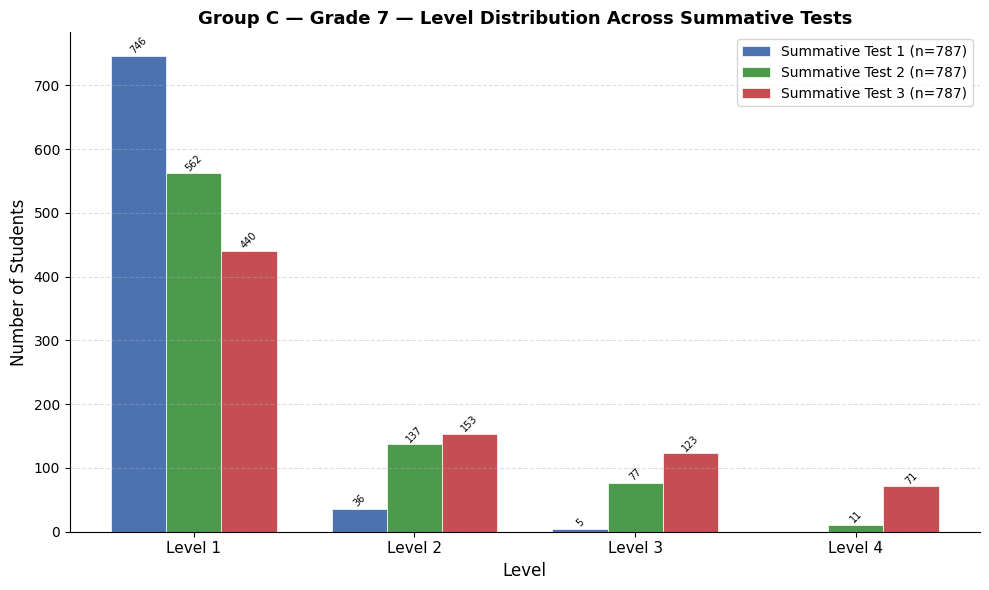

Saved: plots/group_c_level_distribution_combined_07.png


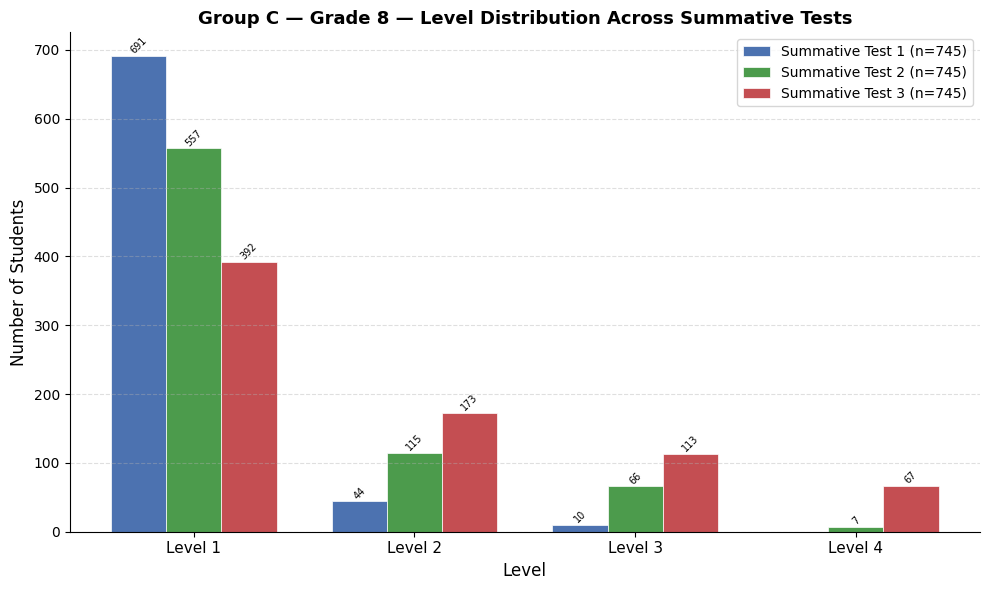

Saved: plots/group_c_level_distribution_combined_08.png


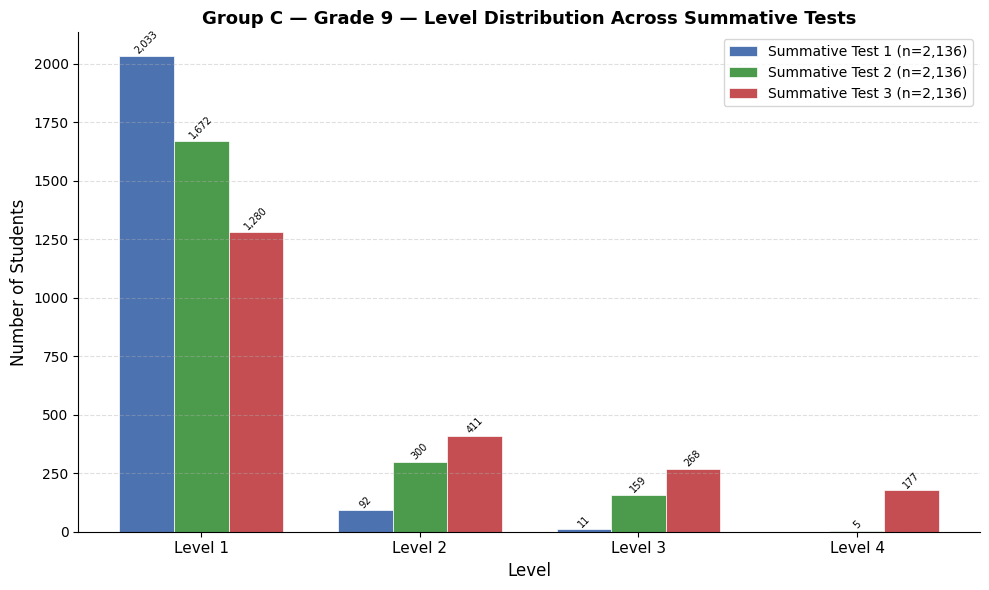

Saved: plots/group_c_level_distribution_combined_09.png


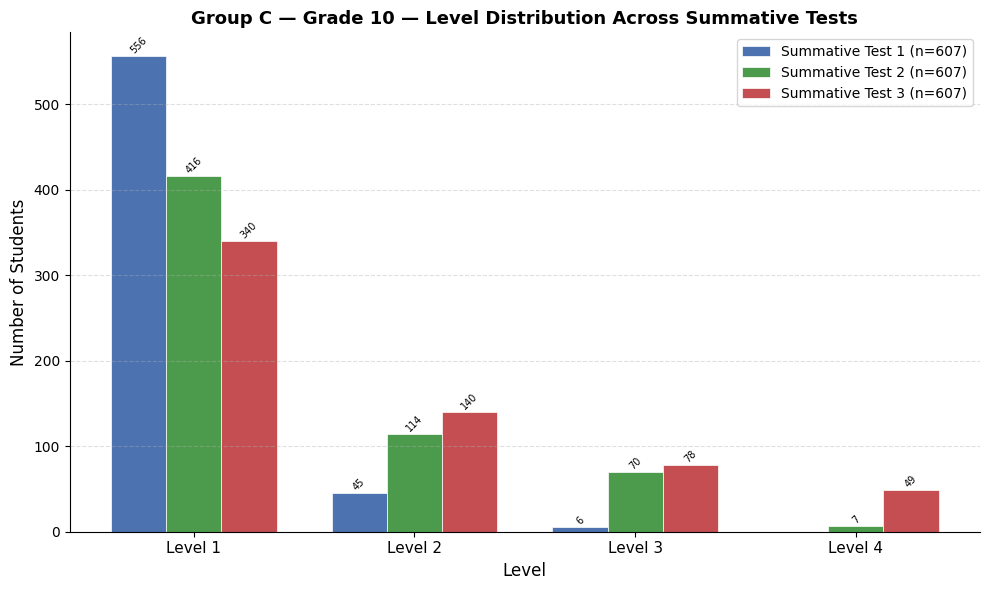

Saved: plots/group_c_level_distribution_combined_10.png


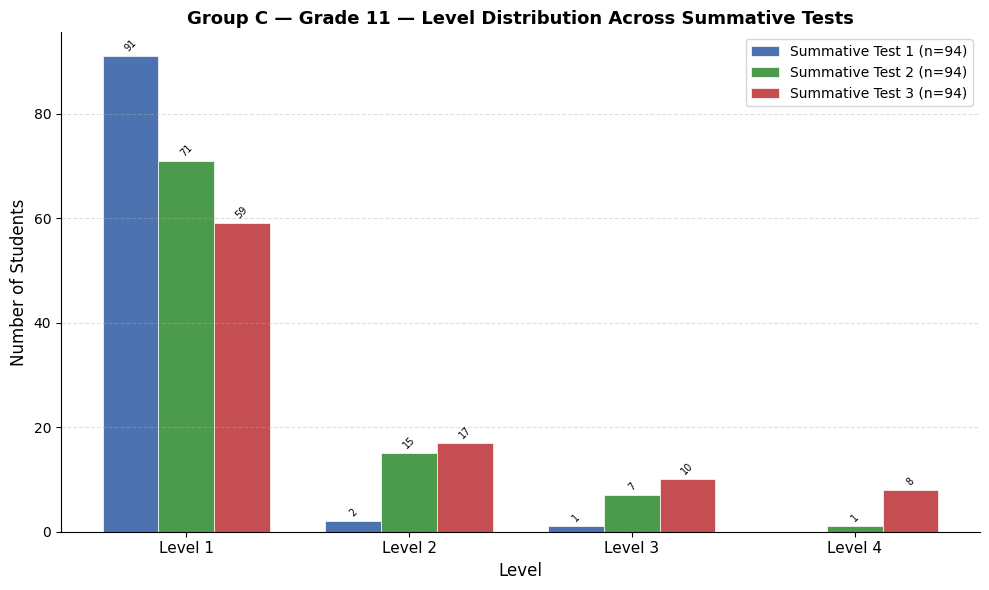

Saved: plots/group_c_level_distribution_combined_11.png


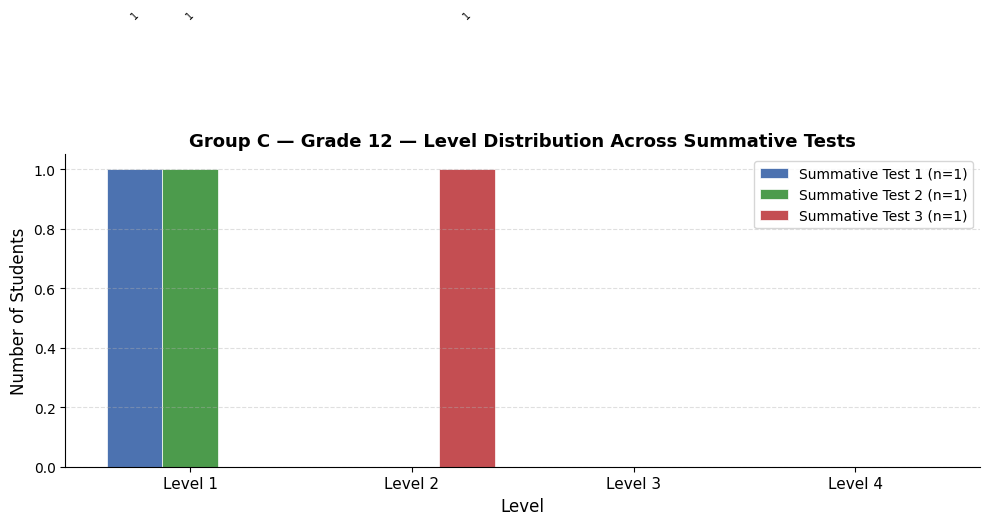

Saved: plots/group_c_level_distribution_combined_12.png


In [8]:
# --- Per-grade grouped bar chart: all 3 tests on one figure per grade ---
for grade in grades_present:
    grade_data = scored_df[scored_df["GradeLevelCode"] == grade]
    if len(grade_data) == 0:
        continue

    fig, ax = plt.subplots(figsize=(10, 6))

    x = np.array([1, 2, 3, 4])
    width = 0.25
    offsets = [-width, 0, width]
    test_colors = ["#4C72B0", "#4C9B4C", "#C44E52"]

    for i, test_num in enumerate([1, 2, 3]):
        test_data = grade_data[grade_data["TestNumber"] == test_num]["Level"].dropna()
        counts = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        bars = ax.bar(x + offsets[i], counts.values, width=width,
                      color=test_colors[i], edgecolor="white", linewidth=0.5,
                      label=f"Summative Test {test_num} (n={len(test_data):,})")

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=7, rotation=45)

    ax.set_xticks(x)
    ax.set_xticklabels(["Level 1", "Level 2", "Level 3", "Level 4"], fontsize=11)
    ax.set_xlabel("Level", fontsize=12)
    ax.set_ylabel("Number of Students", fontsize=12)
    ax.set_title(f"{group_name} — {grade_labels[grade]} — Level Distribution Across Summative Tests",
                 fontsize=13, fontweight="bold")
    ax.legend(fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"plots/group_c_level_distribution_combined_{grade}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/group_c_level_distribution_combined_{grade}.png")

In [10]:
# --- Merge SED status into scored_df ---
scored_df = scored_df.merge(
    enrollment_all[enrollment_all["SSID"].isin(group_ssids)][["SSID", "SocioeconomicallyDisadvantaged"]].dropna(),
    on="SSID", how="left"
)

sed_values = sorted(scored_df["SocioeconomicallyDisadvantaged"].dropna().unique())
print(f"Unique SED values: {sed_values}")

Unique SED values: ['N', 'Y']


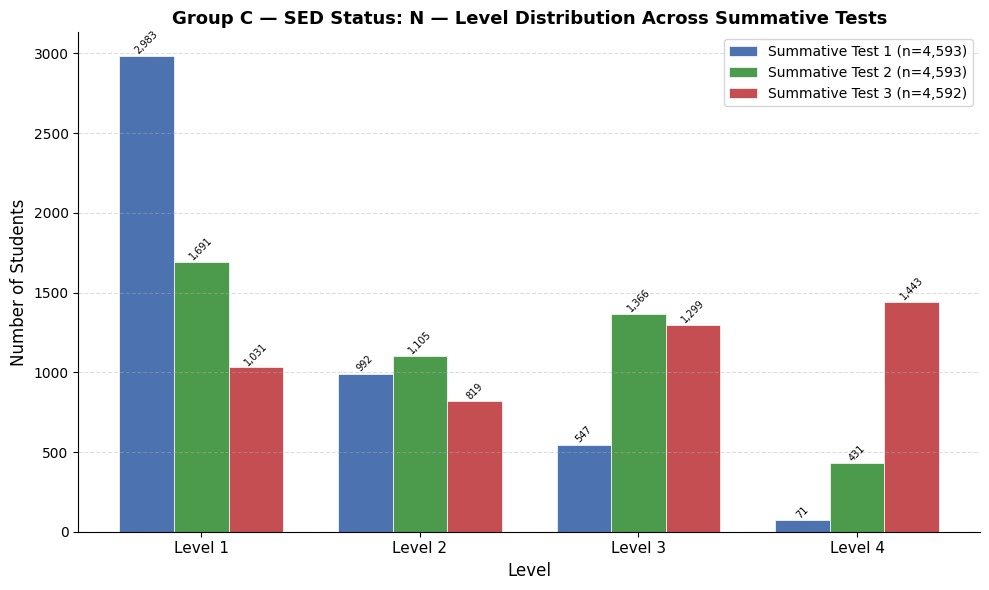

Saved: plots/group_c_level_distribution_sed_N.png


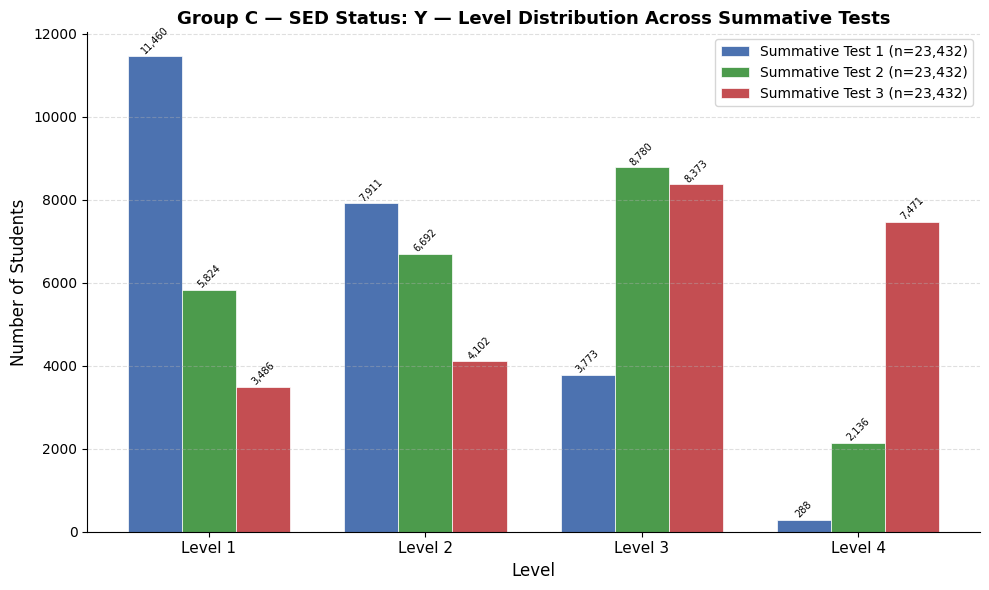

Saved: plots/group_c_level_distribution_sed_Y.png


In [11]:
# --- Per-SED grouped bar chart: all 3 tests on one figure per SED value ---
for sed in sed_values:
    sed_data = scored_df[scored_df["SocioeconomicallyDisadvantaged"] == sed]
    if len(sed_data) == 0:
        continue

    fig, ax = plt.subplots(figsize=(10, 6))

    x = np.array([1, 2, 3, 4])
    width = 0.25
    offsets = [-width, 0, width]
    test_colors = ["#4C72B0", "#4C9B4C", "#C44E52"]

    for i, test_num in enumerate([1, 2, 3]):
        test_data = sed_data[sed_data["TestNumber"] == test_num]["Level"].dropna()
        counts = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        bars = ax.bar(x + offsets[i], counts.values, width=width,
                      color=test_colors[i], edgecolor="white", linewidth=0.5,
                      label=f"Summative Test {test_num} (n={len(test_data):,})")

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=7, rotation=45)

    ax.set_xticks(x)
    ax.set_xticklabels(["Level 1", "Level 2", "Level 3", "Level 4"], fontsize=11)
    ax.set_xlabel("Level", fontsize=12)
    ax.set_ylabel("Number of Students", fontsize=12)
    ax.set_title(f"{group_name} — SED Status: {sed} — Level Distribution Across Summative Tests",
                 fontsize=13, fontweight="bold")
    ax.legend(fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_sed = str(sed).replace(" ", "_")
    plt.savefig(f"plots/group_c_level_distribution_sed_{safe_sed}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/group_c_level_distribution_sed_{safe_sed}.png")

In [12]:
# --- Merge ParentGuardianHighestEducationLevelCode into scored_df ---
scored_df = scored_df.merge(
    enrollment_all[enrollment_all["SSID"].isin(group_ssids)][["SSID", "ParentGuardianHighestEducationLevelCode"]].dropna(),
    on="SSID", how="left"
)

edu_values = sorted(scored_df["ParentGuardianHighestEducationLevelCode"].dropna().unique())
print(f"Unique Parent Education Level values: {edu_values}")

Unique Parent Education Level values: [np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0)]


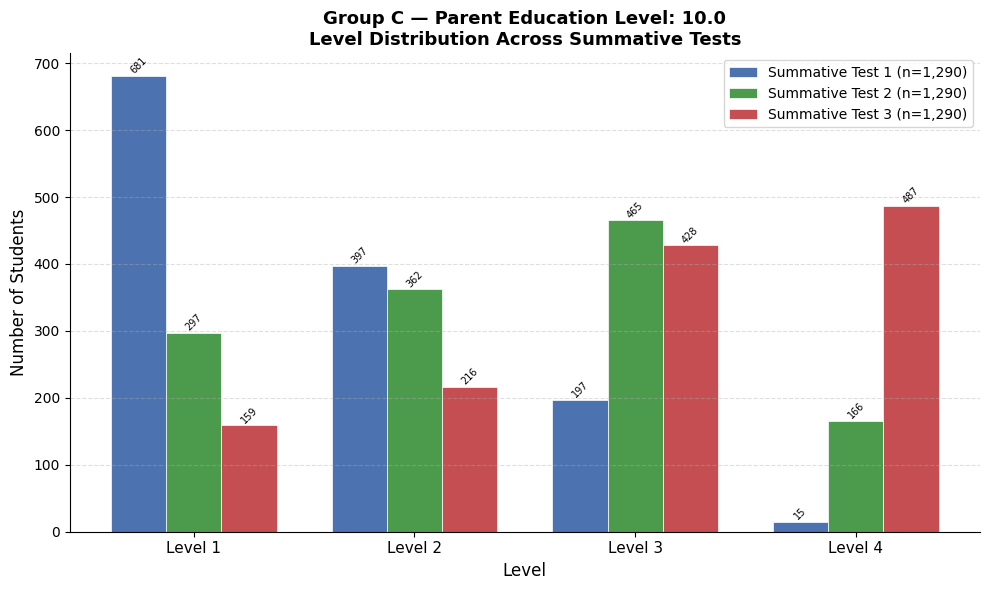

Saved: plots/group_c_level_distribution_edu_10.0.png


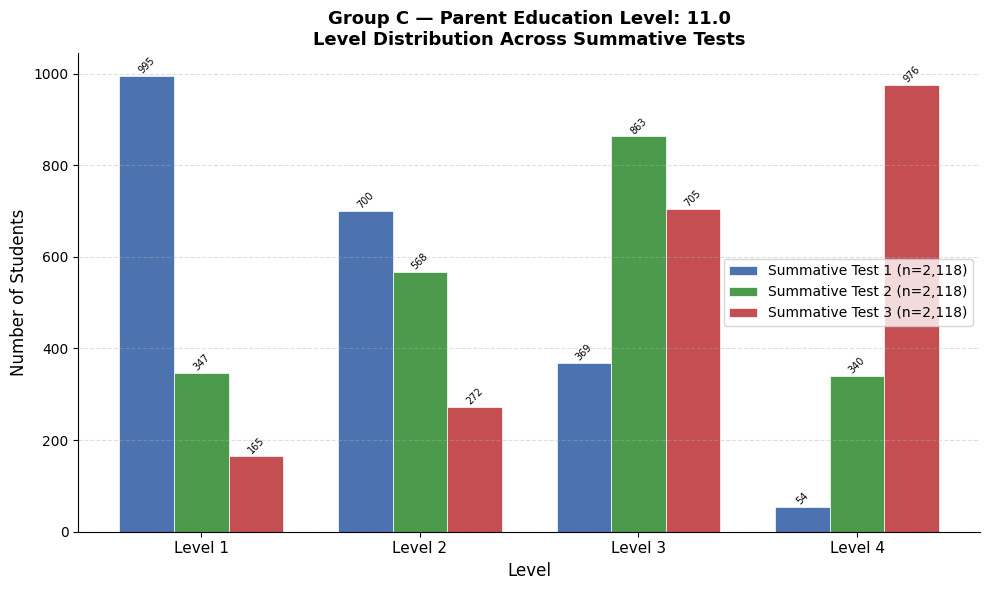

Saved: plots/group_c_level_distribution_edu_11.0.png


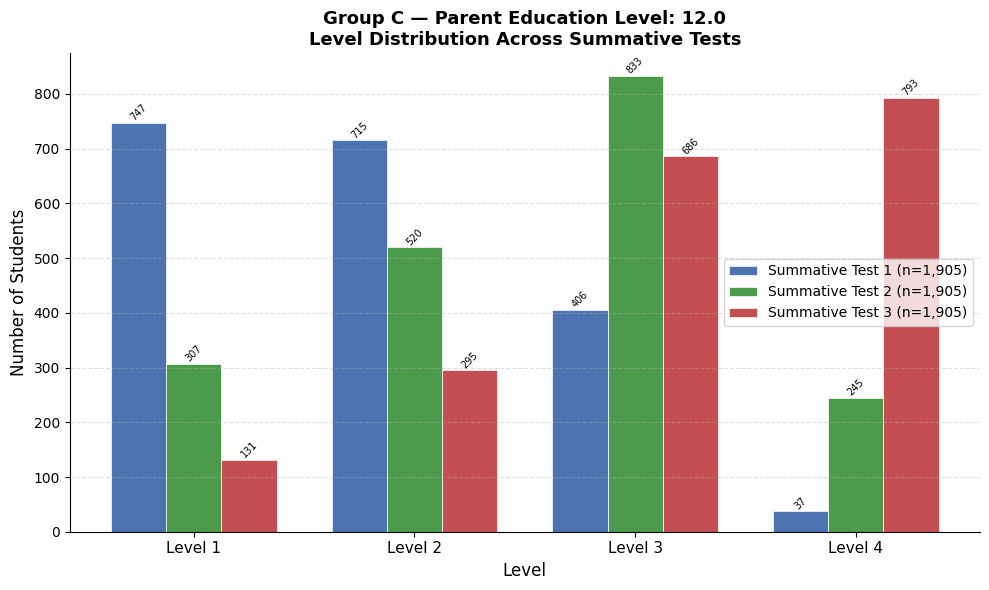

Saved: plots/group_c_level_distribution_edu_12.0.png


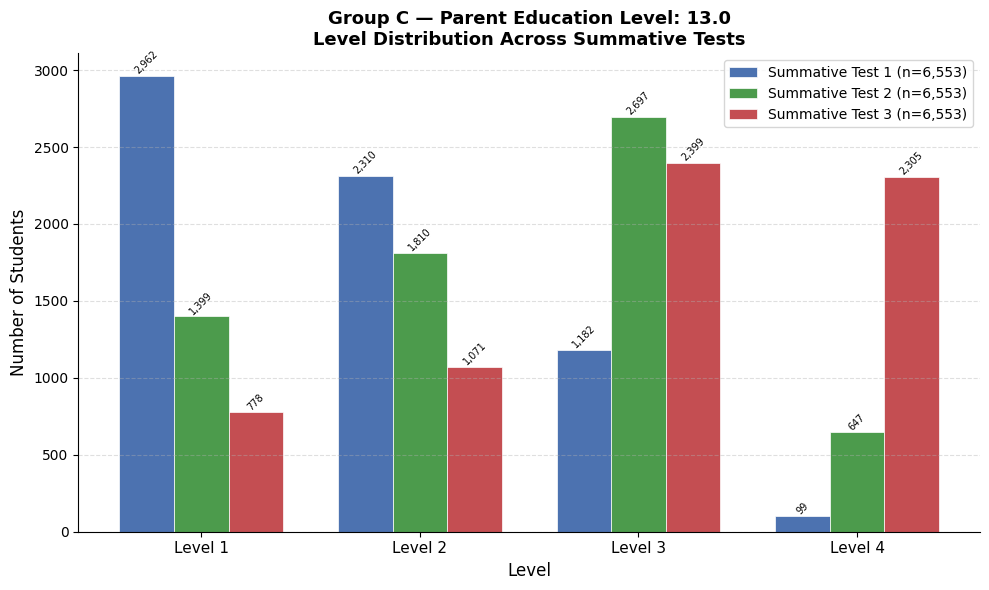

Saved: plots/group_c_level_distribution_edu_13.0.png


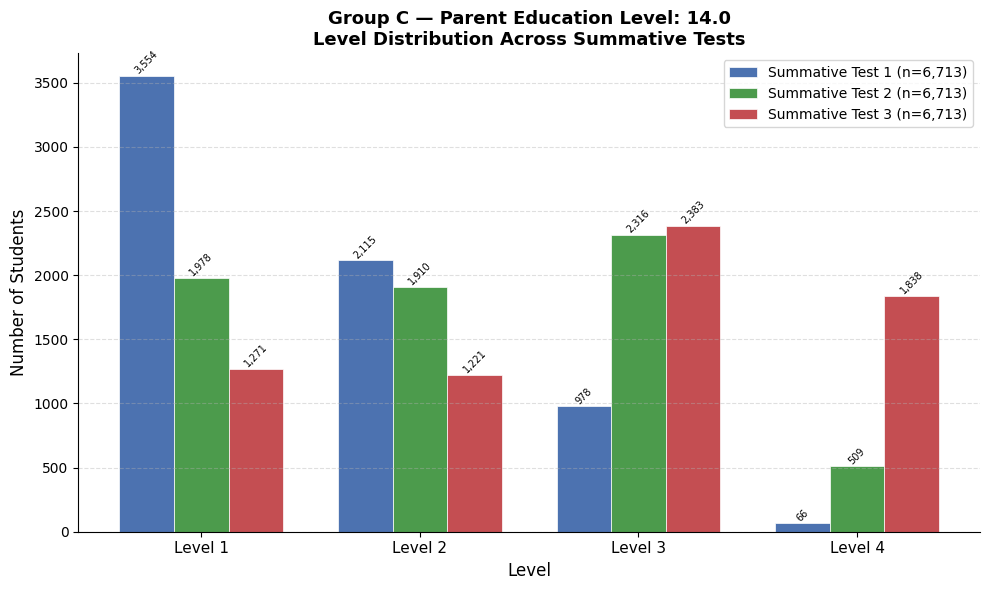

Saved: plots/group_c_level_distribution_edu_14.0.png


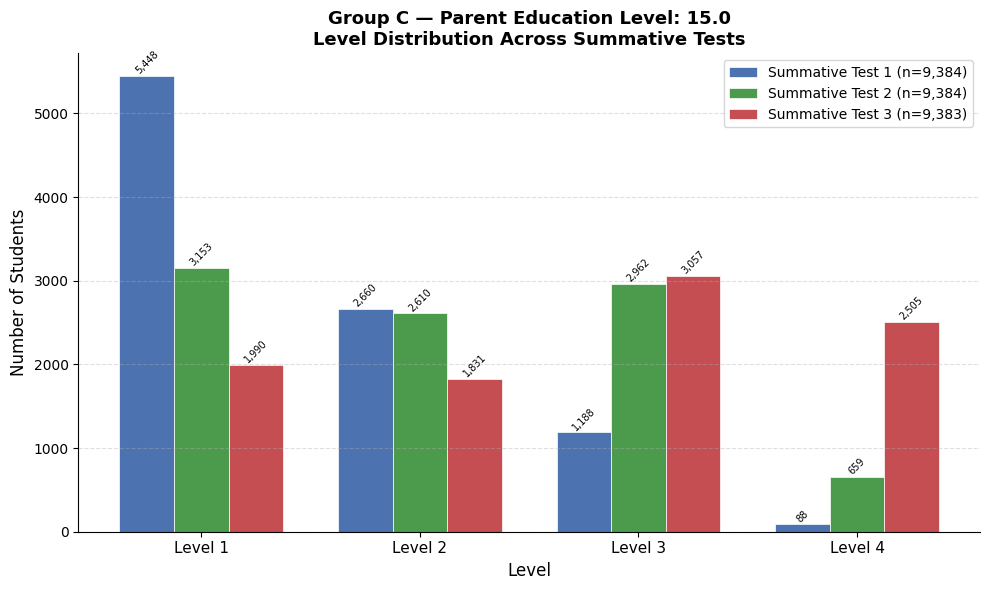

Saved: plots/group_c_level_distribution_edu_15.0.png


In [13]:
# --- Per-Parent Education Level grouped bar chart ---
for edu in edu_values:
    edu_data = scored_df[scored_df["ParentGuardianHighestEducationLevelCode"] == edu]
    if len(edu_data) == 0:
        continue

    fig, ax = plt.subplots(figsize=(10, 6))

    x = np.array([1, 2, 3, 4])
    width = 0.25
    offsets = [-width, 0, width]
    test_colors = ["#4C72B0", "#4C9B4C", "#C44E52"]

    for i, test_num in enumerate([1, 2, 3]):
        test_data = edu_data[edu_data["TestNumber"] == test_num]["Level"].dropna()
        counts = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        bars = ax.bar(x + offsets[i], counts.values, width=width,
                      color=test_colors[i], edgecolor="white", linewidth=0.5,
                      label=f"Summative Test {test_num} (n={len(test_data):,})")

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=7, rotation=45)

    ax.set_xticks(x)
    ax.set_xticklabels(["Level 1", "Level 2", "Level 3", "Level 4"], fontsize=11)
    ax.set_xlabel("Level", fontsize=12)
    ax.set_ylabel("Number of Students", fontsize=12)
    ax.set_title(f"{group_name} — Parent Education Level: {edu}\n"
                 f"Level Distribution Across Summative Tests",
                 fontsize=13, fontweight="bold")
    ax.legend(fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_edu = str(edu).replace(" ", "_").replace("/", "_")
    plt.savefig(f"plots/group_c_level_distribution_edu_{safe_edu}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/group_c_level_distribution_edu_{safe_edu}.png")

In [14]:
# --- Merge PrimaryLanguageCode into scored_df ---
scored_df = scored_df.merge(
    enrollment_all[enrollment_all["SSID"].isin(group_ssids)][["SSID", "PrimaryLanguageCode"]].dropna(),
    on="SSID", how="left"
)

# --- Map to Spanish / Non-Spanish ---
scored_df["LanguageGroup"] = scored_df["PrimaryLanguageCode"].apply(
    lambda x: "Spanish" if str(x).strip() == "01" else "Non-Spanish"
)

print("Language group counts:")
print(scored_df[scored_df["TestNumber"] == 1]["LanguageGroup"].value_counts())

Language group counts:
LanguageGroup
Spanish        20836
Non-Spanish     7219
Name: count, dtype: int64


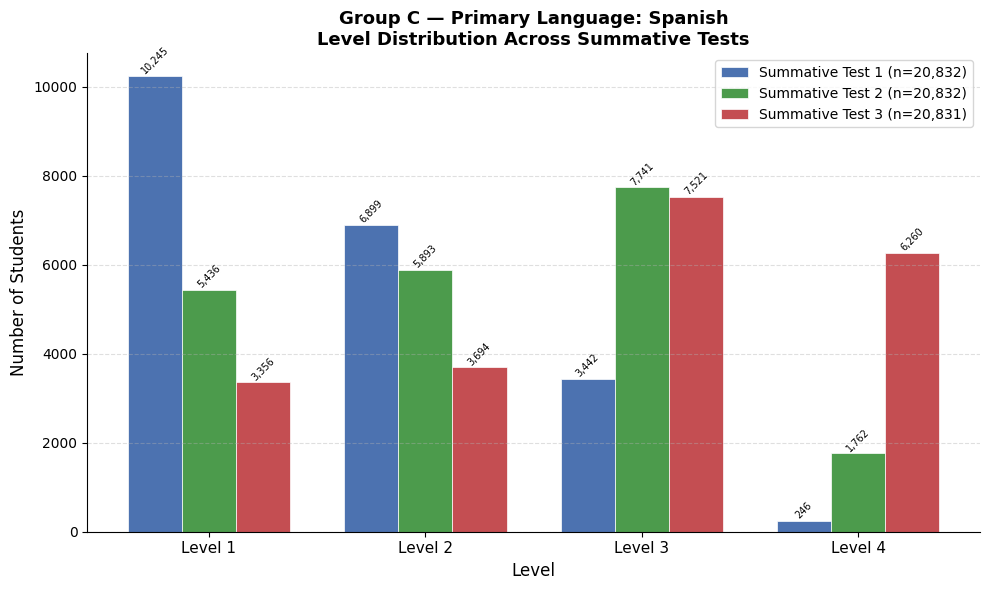

Saved: plots/group_c_level_distribution_lang_spanish.png


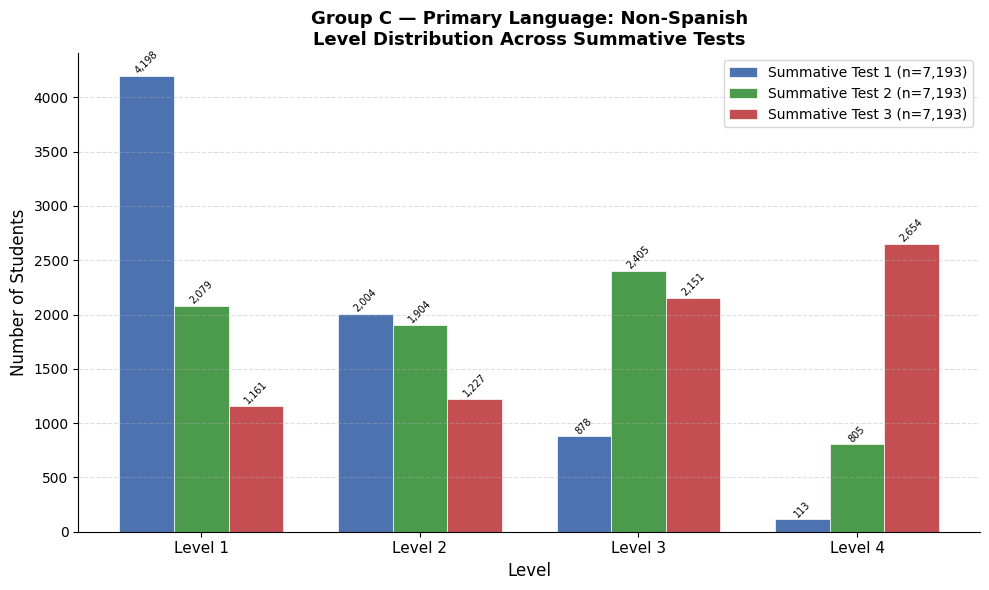

Saved: plots/group_c_level_distribution_lang_non_spanish.png


In [15]:
# --- Per-Language Group grouped bar chart ---
for lang_group in ["Spanish", "Non-Spanish"]:
    lang_data = scored_df[scored_df["LanguageGroup"] == lang_group]
    if len(lang_data) == 0:
        continue

    fig, ax = plt.subplots(figsize=(10, 6))

    x = np.array([1, 2, 3, 4])
    width = 0.25
    offsets = [-width, 0, width]
    test_colors = ["#4C72B0", "#4C9B4C", "#C44E52"]

    for i, test_num in enumerate([1, 2, 3]):
        test_data = lang_data[lang_data["TestNumber"] == test_num]["Level"].dropna()
        counts = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        bars = ax.bar(x + offsets[i], counts.values, width=width,
                      color=test_colors[i], edgecolor="white", linewidth=0.5,
                      label=f"Summative Test {test_num} (n={len(test_data):,})")

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=7, rotation=45)

    ax.set_xticks(x)
    ax.set_xticklabels(["Level 1", "Level 2", "Level 3", "Level 4"], fontsize=11)
    ax.set_xlabel("Level", fontsize=12)
    ax.set_ylabel("Number of Students", fontsize=12)
    ax.set_title(f"{group_name} — Primary Language: {lang_group}\n"
                 f"Level Distribution Across Summative Tests",
                 fontsize=13, fontweight="bold")
    ax.legend(fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"plots/group_c_level_distribution_lang_{lang_group.lower().replace('-', '_')}.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/group_c_level_distribution_lang_{lang_group.lower().replace('-', '_')}.png")